# Plot Fortran

/var/folders/4b/21l8l7f16454_gmz0828vrsr0000gn/T/ipykernel_44856/3662212202.py:100: UserWarning: Data has no positive values, and therefore cannot be log-scaled.
  ax.set_yscale('log')


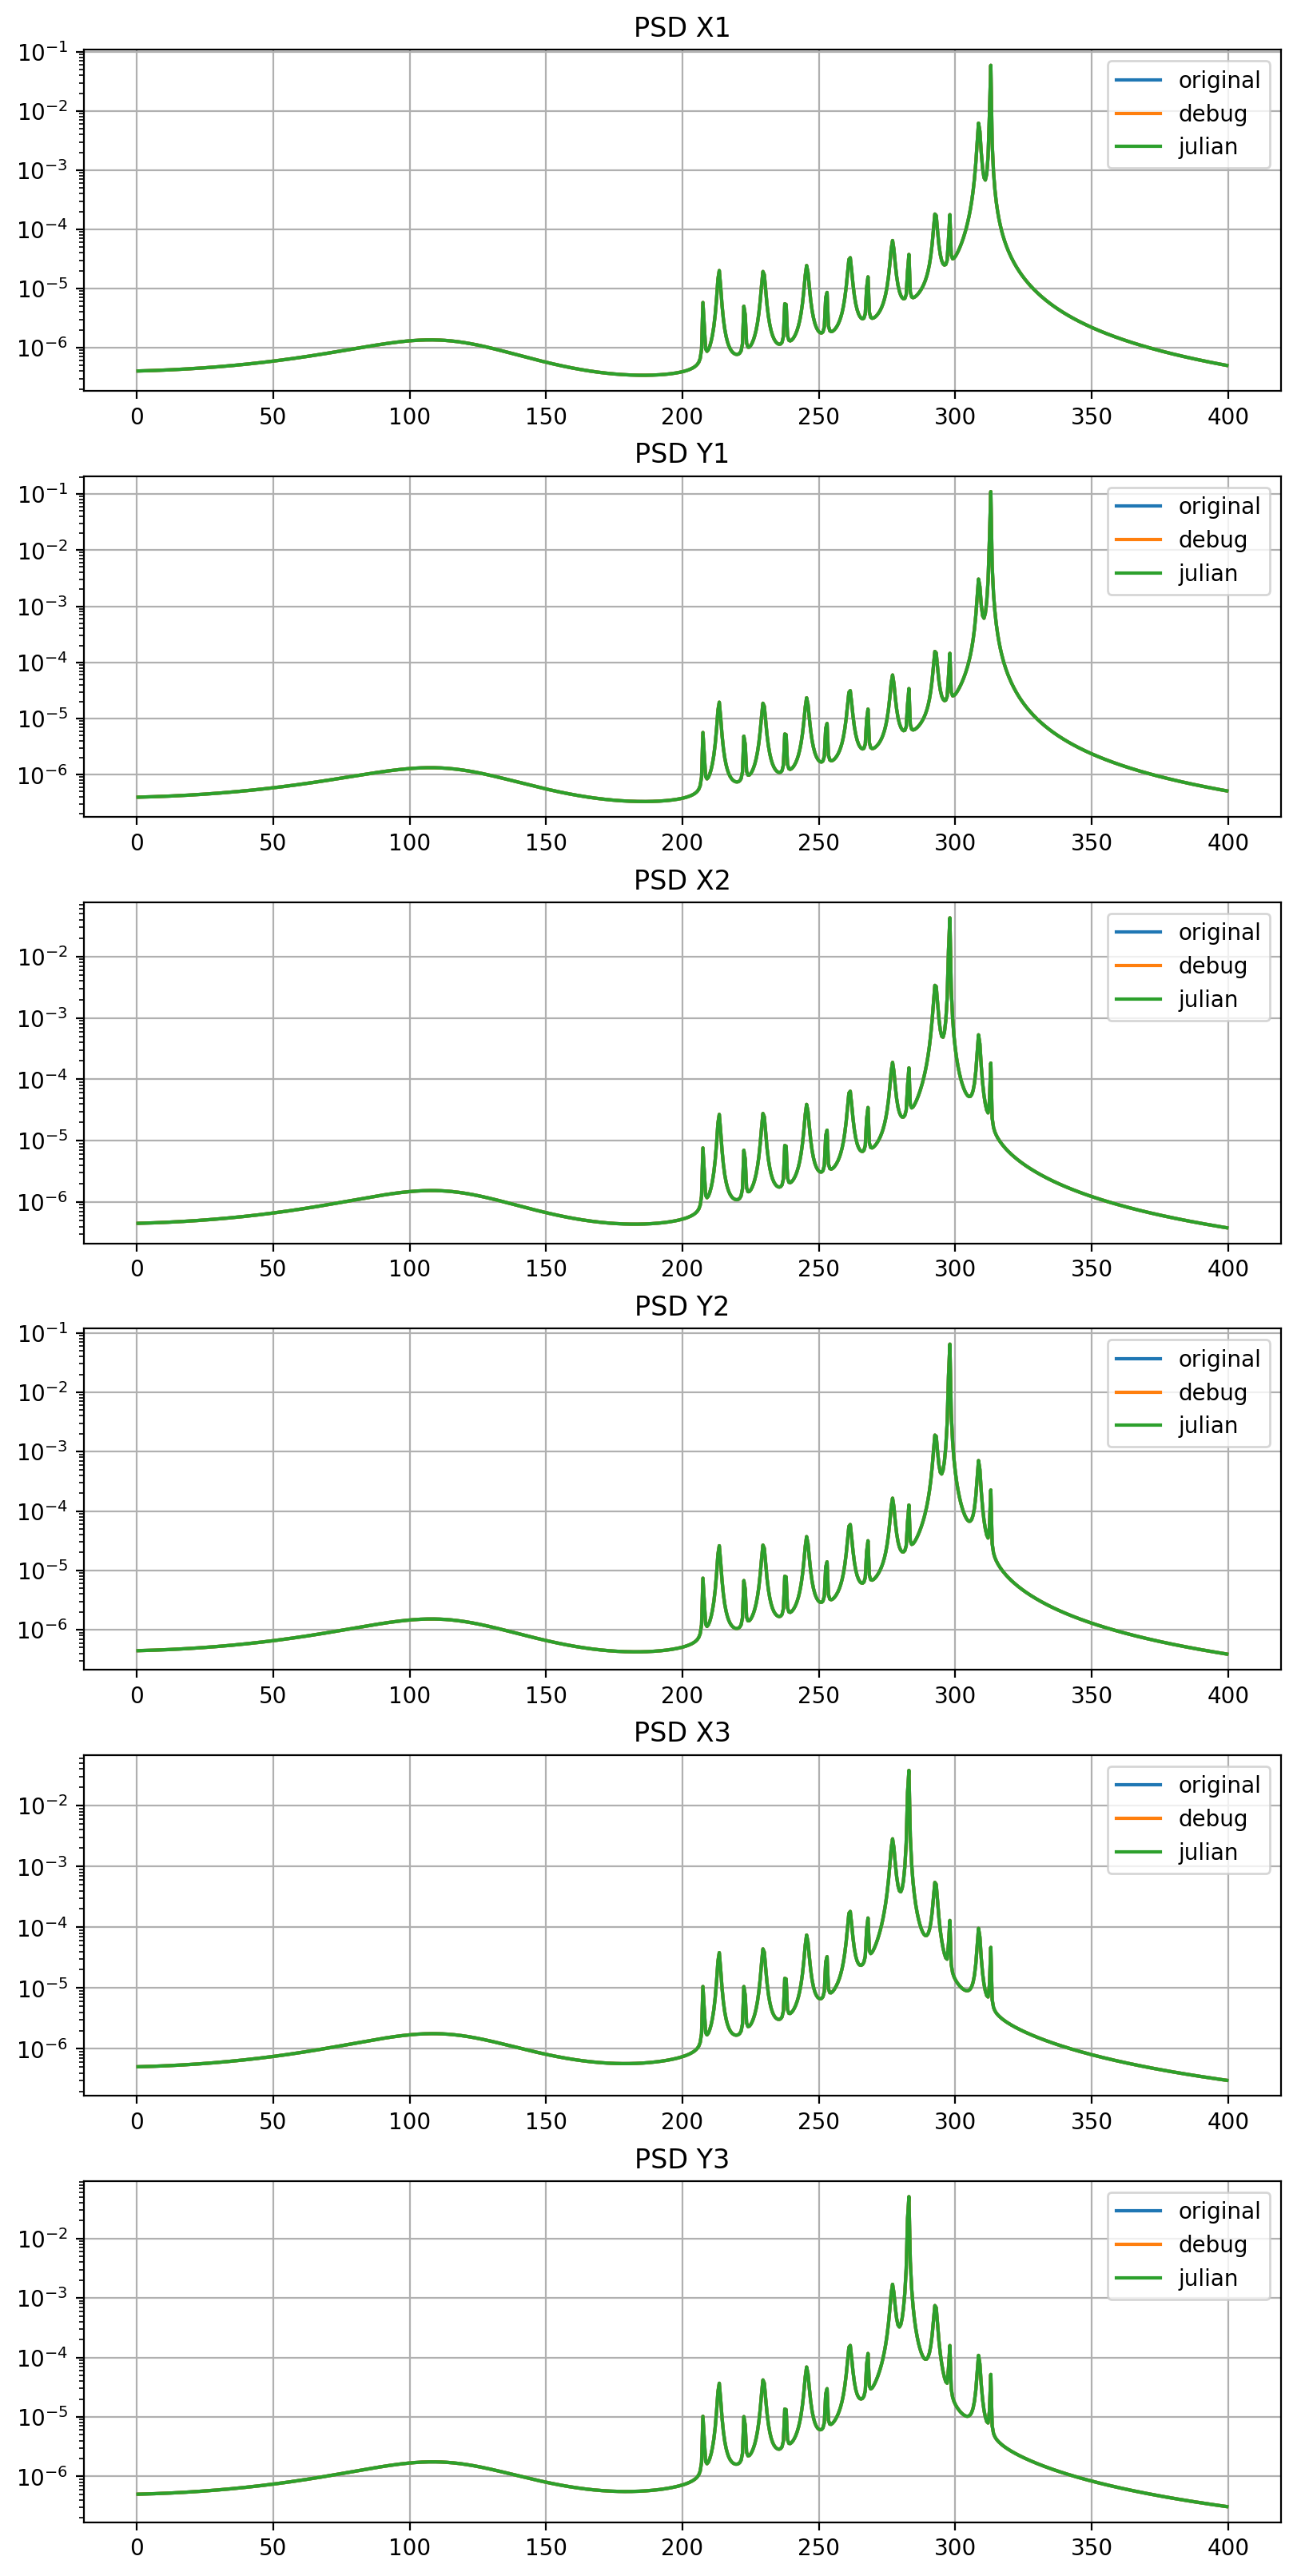

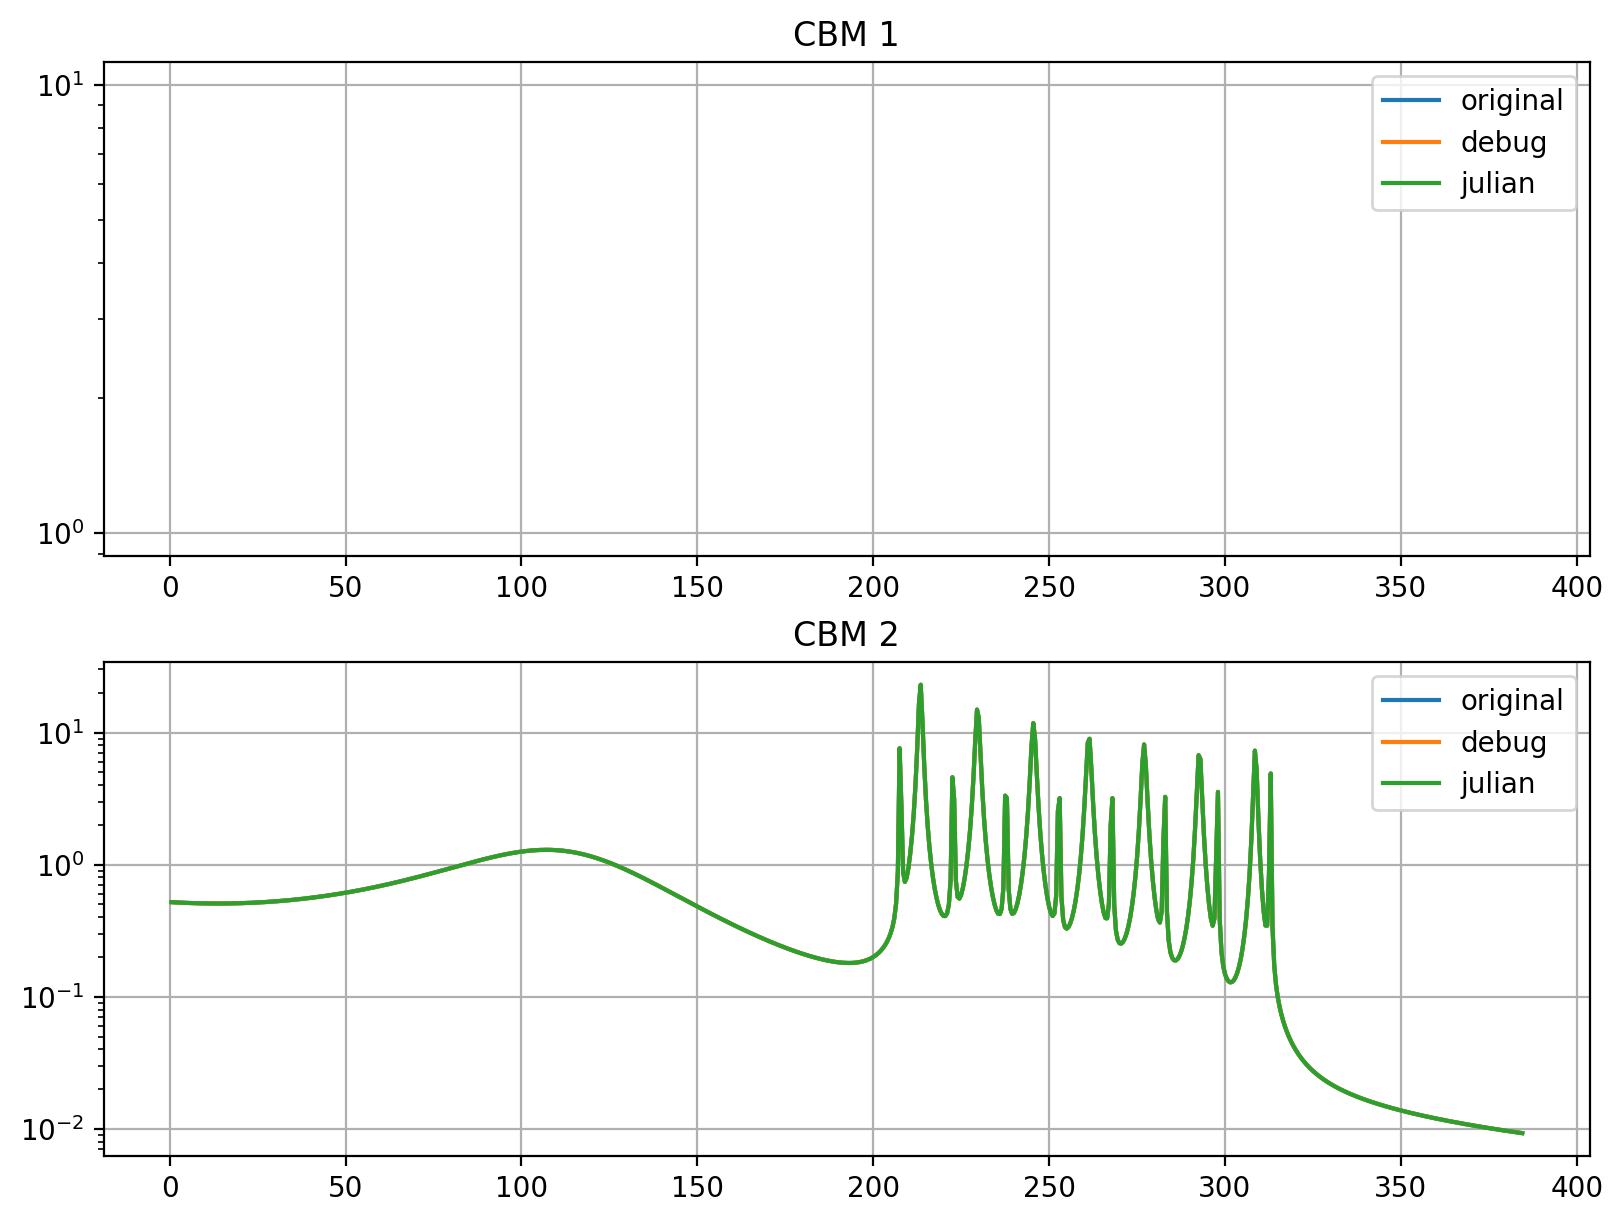

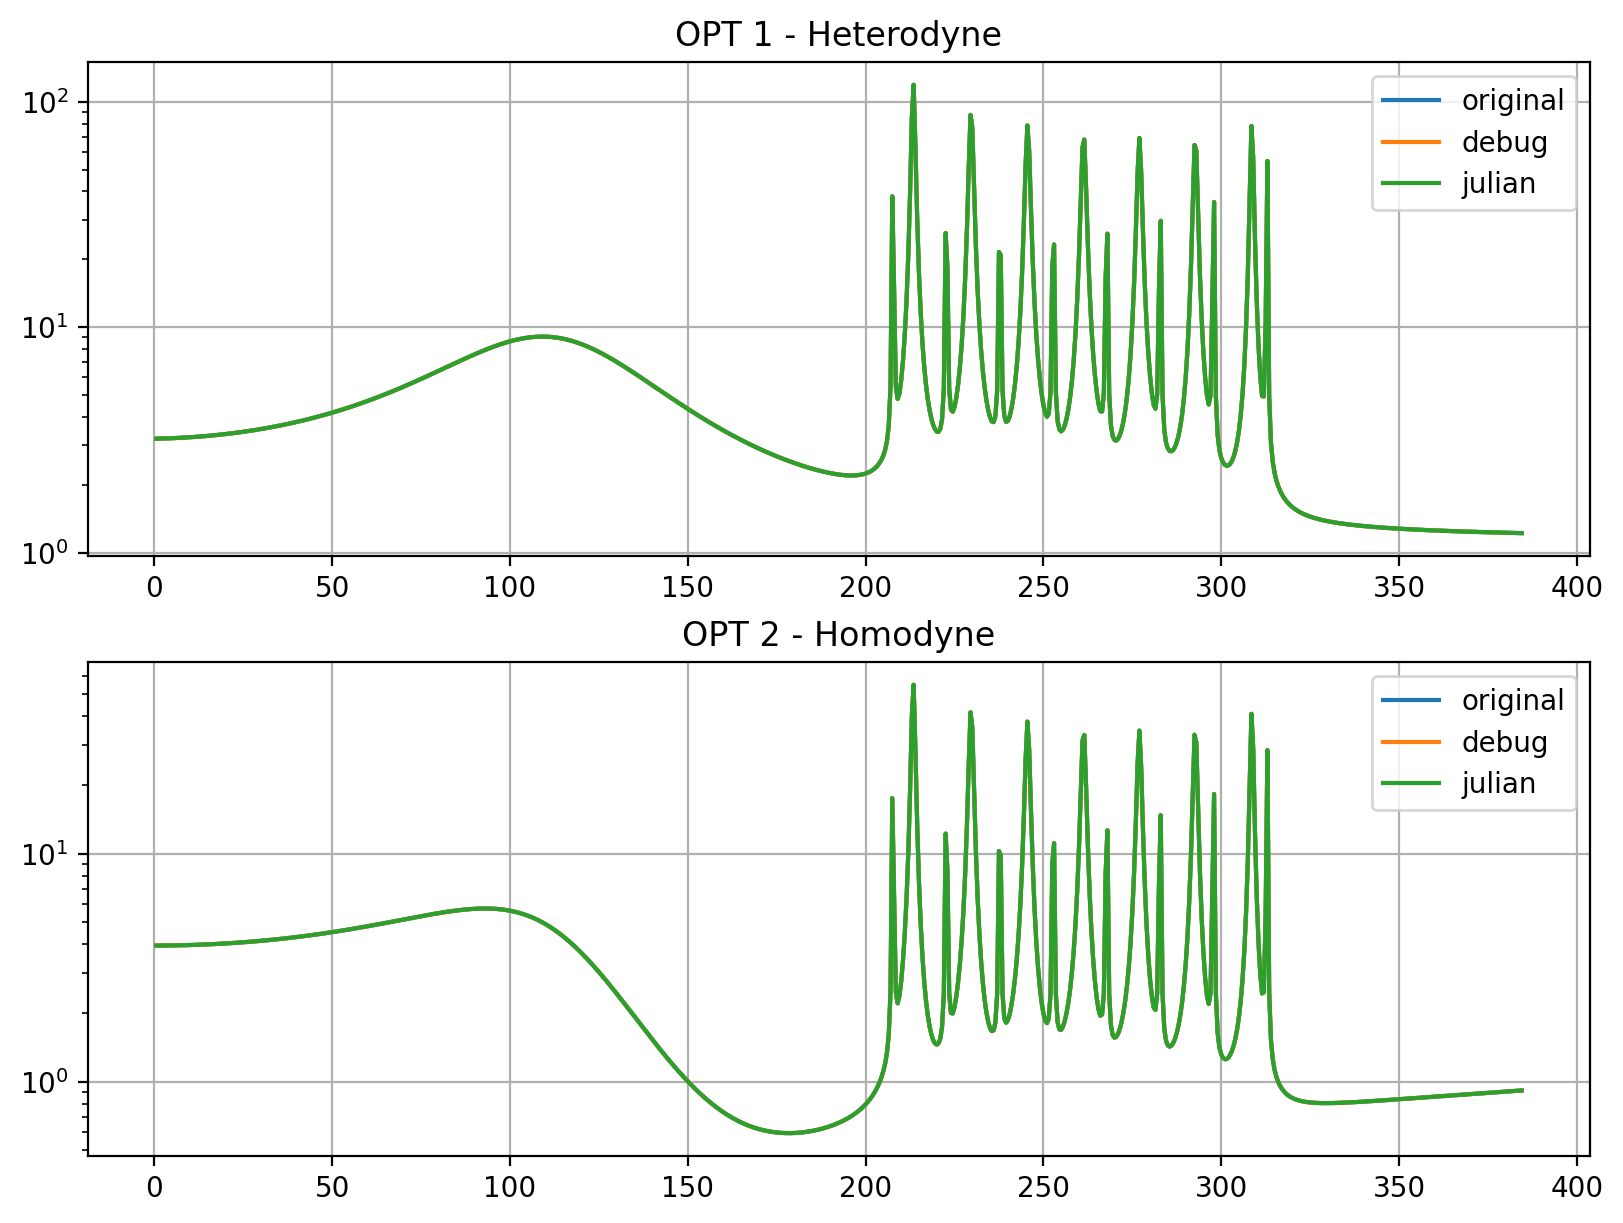

In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# NOTE: to get the data from this fortran scripts, run
# gfortran -O2 -llapack NParticle.f90  3DEQRom.f90 ParametersNpair.f90 Suscept.f90 PSD.f90 NoiseVec2D.f90; ./a.out

base_root = '/Users/julian/Documents/PhD/projects/2024-08 -- Multidimensional QLT/FORTRAN/CBM.Fortran-'
root_original = base_root + 'ORIGINAL/'
root_debug = base_root + 'DEBUG/'
root_julian = base_root + 'JULIAN/'

plt.rcParams['figure.dpi'] = 200
plt.rcParams['figure.figsize'] = (8, 6)

roots = {
    'original': root_original,
    'debug': root_debug,
    'julian': root_julian,
}

figsize = (10, 8)
dpi = 300
PSD_fig = plt.figure(layout='constrained', figsize=(8, 16))
CBM_fig = plt.figure(layout='constrained')
OPT_fig = plt.figure(layout='constrained')

PSD_ax_dict = PSD_fig.subplot_mosaic(
    [
        # ['PSD_1', 'PSD_2'],
        # ['PSD_3', 'PSD_4'],
        # ['PSD_5', 'PSD_6'],
        ['PSD_1'],
        ['PSD_2'],
        ['PSD_3'],
        ['PSD_4'],
        ['PSD_5'],
        ['PSD_6'],
    ],
)
PSD_ax_1 = PSD_ax_dict['PSD_1']
PSD_ax_2 = PSD_ax_dict['PSD_2']
PSD_ax_3 = PSD_ax_dict['PSD_3']
PSD_ax_4 = PSD_ax_dict['PSD_4']
PSD_ax_5 = PSD_ax_dict['PSD_5']
PSD_ax_6 = PSD_ax_dict['PSD_6']

CBM_ax_dict = CBM_fig.subplot_mosaic([
    ['CBM_1'],
    ['CBM_2'],
])
CBM_ax_1 = CBM_ax_dict['CBM_1']
CBM_ax_2 = CBM_ax_dict['CBM_2']

OPT_ax_dict = OPT_fig.subplot_mosaic([
    ['OPT_1'],
    ['OPT_2'],
])
OPT_ax_1 = OPT_ax_dict['OPT_1']
OPT_ax_2 = OPT_ax_dict['OPT_2']

for root_name, root in roots.items():
    XYZ_file = root + 'FTanXYZ.dat'
    CBM_file = root +'FTCBM.dat'
    OPT_file = root + 'FTanOPT.dat'

    xyz_data = np.loadtxt(XYZ_file)
    cbm_data = np.loadtxt(CBM_file)
    opt_data = np.loadtxt(OPT_file)


    PSD_ax_1.plot(xyz_data[:, 0], xyz_data[:, 1], label=root_name)
    PSD_ax_2.plot(xyz_data[:, 0], xyz_data[:, 2], label=root_name)
    PSD_ax_3.plot(xyz_data[:, 0], xyz_data[:, 3], label=root_name)
    PSD_ax_4.plot(xyz_data[:, 0], xyz_data[:, 4], label=root_name)
    PSD_ax_5.plot(xyz_data[:, 0], xyz_data[:, 5], label=root_name)
    PSD_ax_6.plot(xyz_data[:, 0], xyz_data[:, 6], label=root_name)

    CBM_ax_1.plot(cbm_data[:, 0], cbm_data[:, 1], label=root_name)
    CBM_ax_2.plot(cbm_data[:, 0], cbm_data[:, 2], label=root_name)

    OPT_ax_1.plot(opt_data[:, 0], opt_data[:, 1], label=root_name)
    OPT_ax_2.plot(opt_data[:, 0], opt_data[:, 2], label=root_name)

    PSD_ax_1.set_title('PSD X1')
    PSD_ax_2.set_title('PSD Y1')
    PSD_ax_3.set_title('PSD X2')
    PSD_ax_4.set_title('PSD Y2')
    PSD_ax_5.set_title('PSD X3')
    PSD_ax_6.set_title('PSD Y3')

    CBM_ax_1.set_title('CBM 1')
    CBM_ax_2.set_title('CBM 2')

    OPT_ax_1.set_title('OPT 1 - Heterodyne')
    OPT_ax_2.set_title('OPT 2 - Homodyne')

for ax_dict in [PSD_ax_dict, CBM_ax_dict, OPT_ax_dict]:
    for ax in ax_dict.values():
        ax.set_yscale('log')
        ax.legend()
        ax.grid()

plt.show()


In [2]:
# kHz step size of Fortran data
xyz_data[:, 0][1] - xyz_data[:, 0][0]

0.5

# Spectral method comparisons

In [1]:
from multiphysics import *
import matplotlib.pyplot as plt
from pprint import pprint as pp
import cv2

plt.rcParams['figure.dpi'] = 150
plt.rcParams['figure.figsize'] = (8, 6)

ω0 = 300*kHz
toy_params = {
    # 'model': 'spread',
    # 'ω_mid': ω0,
    # 'ω_span': 100*kHz,
    # 'Ω_gap': 15*kHz,

    'model': 'pairs',
    'first_Ωx': 312*kHz,
    'Ω_gap': 15*kHz,
    'Ωz_to_Ωx_multiplier': 10,

    'toy_g': -40*kHz,
    # 'gxy': 0*kHz,
    # 'gxz': 0*kHz,
    # 'gyz': 0*kHz,

    # 'toy_Γ': 1e-5*Hz,
    'use_Γ_formula': True,
    'vth': 500,  # m/s

    # 'φ1': 0*degrees,
    # 'φ2': 45*degrees,
}

cavity_kwargs = {
    # 'Δ': -1.5*ω0,
    # 'κ': ω0/1.5,
    'Δ': -450*kHz,
    'κ': 390.625*kHz,
    'θhom': π/4,
}

gas_kwargs = {
    'P': 1e-6*mbar,
    'T': 300*K,
}

N, ax = 8, 2
ω_low, ω_high, ω_step = 0, 400, 0.5
mph = MultiPhysics(
    num_traps=N,
    Cartesian_axes_per_trap=ax,
    ω_range=np.arange(ω_low, ω_high, ω_step) * kHz,

    cavity_kwargs=cavity_kwargs,
    gas_kwargs=gas_kwargs,
    toy_params=toy_params,

    setup_hybridisation_power_series=N * ax < 4,
    compare_Rjk_calculations=N * ax < 4,
)

mph.info
mph.cavity.info
mph.gas.info
mph.info_per_dimension

# φ12 = mph.dimensions['x1'].φ - mph.dimensions['x2'].φ / degrees
# φ13 = mph.dimensions['x1'].φ - mph.dimensions['x3'].φ / degrees
# φ14 = mph.dimensions['x1'].φ - mph.dimensions['x4'].φ / degrees

title_str = (
    # f'Φ/2π = {mph.dimensions["x1"].Φ / (2*π)}'
    # f'; '
    # f'φ1j = ['
    # f'{φ12}'
    # f', {φ13}'
    # f', {φ14}'
    # f']°'
)
print(title_str)

image_dicts = {}
spectral_types = [
    'PSDs',
    'homodyne',
    'heterodyne',
]
QLTM = QuantumLinearTheoryMethod

methods = [
    QLTM.LINEAR_AMPLIFIER_MODEL,
    # QLTM.HYBRID_LINEAR_AMPLIFIER_MODEL,
    QLTM.TNT_LINEAR_AMPLIFIER_MODEL,

    QLTM.NUMERICAL_HYBRIDISATION,
    # QLTM.POWER_SERIES_HYBRIDISATION,
]

if QLTM.TNT_LINEAR_AMPLIFIER_MODEL in methods:
    spectral_types = ['PSDs']

all_plot_values = {}
for spectral_type in spectral_types:
    image_dicts[spectral_type] = {}
    for method in methods:
        all_plot_values[method] = {}
        print(f'{spectral_type} -- {method}')

        label = spectral_type
        if spectral_type == 'PSDs':
            calc_func = mph.calculate_all_hybridised_position_spectra
            label = mph.labels
        elif spectral_type == 'homodyne':
            calc_func = mph.calculate_homodyne_spectrum
        elif spectral_type == 'heterodyne':
            calc_func = mph.calculate_heterodyne_spectrum

        plot_values = calc_func(method)
        all_plot_values[method][spectral_type] = plot_values

        if spectral_type == 'PSDs':
            PSD_fig = plt.figure(layout='constrained', figsize=(8, 16))
            PSD_ax_dict = PSD_fig.subplot_mosaic([
                ['X1'],
                ['Y1'],
                ['X2'],
                ['Y2'],
                ['X3'],
                ['Y3'],
                # ['X4'],
                # ['Y4'],
                # ['X5'],
                # ['Y5'],
                # ['X6'],
                # ['Y6'],
                # ['X7'],
                # ['Y7'],
                # ['X8'],
                # ['Y8'],
                # ['X1', 'Y1'],
                # ['X2', 'Y2'],
                # ['X3', 'Y3'],
                # ['X4', 'Y4'],
                # ['X5', 'Y5'],
                # ['X6', 'Y6'],
                # ['X7', 'Y7'],
                # ['X8', 'Y8'],
            ])
            PSD_ax_list = list(PSD_ax_dict.values())
            for ii, PSD_ax in enumerate(PSD_ax_list):
                PSD_ax.plot(mph.ω_range / kHz, plot_values[:, ii], label=label[ii])
                PSD_ax.set_yscale('log')
                PSD_ax.legend()
                PSD_ax.set_xlim(ω_low, ω_high)
                PSD_ax.set_ylim(1e-7, 1e1)
            plt.show()

        plt.plot(
            mph.ω_range / kHz,
            plot_values,
            label=label,
        )
        plt.yscale('log')
        plt.legend()
        plt.grid()
        plt.title(title_str)
        plt.xlim(ω_low, ω_high)
        if spectral_type == 'PSDs':
            plt.ylim(1e-7, 1e1)
        figname = f'{spectral_type} -- {method}.png'
        plt.savefig(figname)
        image_dicts[spectral_type][method] = cv2.imread(figname)
        plt.show()

        if spectral_type == 'PSDs':
            for ii, label in enumerate(mph.labels):
                jn = mph.dimensions[label]
                ħΩ = ħ * jn.Ω

                SQQ_area = np.trapz(plot_values[:, ii], mph.ω_range / Hz)
                njn = 0.5 * (SQQ_area - 1)
                print(f'{label=}')
                print(f'n{label} = {njn:.6f} phonons')
                print(f'T{label} via phonons = {njn * ħΩ / kB:.6e} K')

                eqp_f = jn.m * jn.Ω**2 / kB
                q_variance = SQQ_area * jn.zpf**2 / (2*π)
                print(f'T{label} via variance = {eqp_f * q_variance:.6e} K')


method_pairs = []
# comparing 2
if len(methods) >= 2:
    method_pairs.append((methods[0], methods[1]))

# comparing 3
if len(methods) >= 3:
    method_pairs.append((methods[1], methods[2]))
    method_pairs.append((methods[0], methods[2]))

# comparing 4
if len(methods) >= 4:
    method_pairs.append((methods[2], methods[3]))
    method_pairs.append((methods[0], methods[3]))
    method_pairs.append((methods[1], methods[3]))

# comparing 5
if len(methods) >= 5:
    method_pairs.append((methods[3], methods[4]))
    method_pairs.append((methods[0], methods[4]))
    method_pairs.append((methods[1], methods[4]))
    method_pairs.append((methods[2], methods[4]))


def greyscale_diff(image_1, image_2):
    return cv2.cvtColor(cv2.subtract(image_1, image_2), cv2.COLOR_BGR2GRAY)

results_dict = {}
all_results = []
for spectral_type, image_dict in image_dicts.items():

    results_dict[spectral_type] = {}

    for method_pair in method_pairs:
        diff = greyscale_diff(image_dict[method_pair[0]], image_dict[method_pair[1]])
        result = cv2.countNonZero(diff) == 0

        all_results.append(result)
        results_dict[spectral_type][method_pair] = result

assert all(all_results), f'🏴‍☠️🏴‍☠️🏴‍☠️🏴‍☠️🏴‍☠️ Failure present! 🏴‍☠️🏴‍☠️🏴‍☠️🏴‍☠️🏴‍☠️\n{results_dict=}'
print('🎉🎉🎉🎉🎉 all spectral calculation methods agree :) 🎉🎉🎉🎉🎉')
pp(results_dict)


ModuleNotFoundError: No module named 'multiphysics'

# Compare Tania's Fortran to my code

In [6]:
mph.ω_range[:20] / kHz

array([0. , 0.5, 1. , 1.5, 2. , 2.5, 3. , 3.5, 4. , 4.5, 5. , 5.5, 6. ,
       6.5, 7. , 7.5, 8. , 8.5, 9. , 9.5])

In [7]:
xyz_data[:, 0][:20]

array([ 0.5,  1. ,  1.5,  2. ,  2.5,  3. ,  3.5,  4. ,  4.5,  5. ,  5.5,
        6. ,  6.5,  7. ,  7.5,  8. ,  8.5,  9. ,  9.5, 10. ])

In [8]:
xyz_data[:, 1][:20]

array([4.02741e-07, 4.03276e-07, 4.03831e-07, 4.04408e-07, 4.05006e-07,
       4.05625e-07, 4.06264e-07, 4.06925e-07, 4.07608e-07, 4.08312e-07,
       4.09037e-07, 4.09784e-07, 4.10553e-07, 4.11344e-07, 4.12157e-07,
       4.12993e-07, 4.13851e-07, 4.14731e-07, 4.15634e-07, 4.16561e-07])

In [9]:
method = QLTM.LINEAR_AMPLIFIER_MODEL
all_plot_values[method]['PSDs'][:, 0][1:21]

array([4.02740489e-07, 4.03275641e-07, 4.03831527e-07, 4.04408240e-07,
       4.05005875e-07, 4.05624535e-07, 4.06264324e-07, 4.06925352e-07,
       4.07607735e-07, 4.08311590e-07, 4.09037041e-07, 4.09784216e-07,
       4.10553247e-07, 4.11344272e-07, 4.12157432e-07, 4.12992874e-07,
       4.13850749e-07, 4.14731213e-07, 4.15634428e-07, 4.16560559e-07])

In [ ]:
rtol = 1e-5
method = QLTM.LINEAR_AMPLIFIER_MODEL
for ii in range(len(opt_data[:, 1])):
    if not QLTM.TNT_LINEAR_AMPLIFIER_MODEL in all_plot_values.keys():
        assert np.isclose(opt_data[:, 1][ii], all_plot_values[method]['heterodyne'][ii], rtol=rtol)
        assert np.isclose(opt_data[:, 2][ii], all_plot_values[method]['homodyne'][ii], rtol=rtol)
    for jj in range(1, xyz_data.shape[1]):
        # the first column of xyz_data are the frequencies, hence jj and jj - 1
        # the first entries are off shifted off by one, hence ii and ii + 1
        assert np.isclose(xyz_data[:, jj][ii], all_plot_values[method]['PSDs'][:, jj - 1][ii + 1], rtol=rtol)


# Difference in constant values

In [14]:
(kB / 1.4e-23 - 1) * 100

-1.3822142857142672

In [15]:
(ħ / 1.05e-34 - 1) * 100

0.43541120439585246

# DEBUG output at arbitrary frequency value $\omega = 298$ kHz (to compare to Fortran)

In [4]:
print('quanta_per_operator', mph.quantum_factor_per_noise_operator)
print('phases', [dim.φ for dim in mph.dimensions.values()])
print('kappa (kHz)', mph.cavity.κ / kHz)

omega = 298*kHz

print('light_couplings_array')
print(mph.G_array / kHz)

chi_C = mph.cavity.χC(omega)
print(f'{chi_C=}')
chi_C_star = np.conjugate(mph.cavity.χC(-omega))
print(f'{chi_C=}')
eta_0 = mph.cavity.ηm(298*kHz)
print(f'{eta_0=}')

for label, dim in mph.dimensions.items():
    print(f'eta_M {label}', dim.μm(omega))

print('M_norm_array')
ii = 0
for label, dim in mph.dimensions.items():
    print(1 + mph.G_array[ii]**2 * dim.μm(omega) * eta_0)
    ii += 1

print('Beta_M')
ii = 0
for label, dim in mph.dimensions.items():
    print(1j * np.sqrt(mph.cavity.κ) * dim.μm(omega) * mph.G_array[ii])
    ii += 1

print('X1D_noise_vector')
ii = 0
for label, dim in mph.dimensions.items():
    # print(mph.X1D(298*kHz))
    if ii < 4:
        print(label, '1D', dim.Q1D(omega))
    ii += 1


for method in [
    QLTM.LINEAR_AMPLIFIER_MODEL,
    QLTM.NUMERICAL_HYBRIDISATION,
]:
    print(method)
    a_out_hat, a_out_dag = mph.output_light_noise_vectors(method, omega)
    X_noise_vector = mph.hybridised_X(method, omega)
    print(f'{a_out_hat=}')
    print(f'{a_out_dag=}')
    print(f'{X_noise_vector=}')
    mph.calculate_all_hybridised_position_spectra

print('Rjks')
Rx1y1 = Term(1, [('x1', 'y1')])
Rx1x2 = Term(1, [('x1', 'x2')])
Ry1y2 = Term(1, [('y1', 'y2')])
print(mph.hybridisation_term_value(Rx1y1, omega))
print(mph.hybridisation_term_value(Rx1x2, omega))
print(mph.hybridisation_term_value(Ry1y2, omega))


quanta_per_operator [1, 0, 20404480.883576326, 20404479.883576326, 20306851.793224283, 20306850.793224283, 21435010.170625634, 21435009.170625634, 21327296.556702893, 21327295.556702893, 22575170.232892957, 22575169.232892957, 22455724.893036377, 22455723.893036377, 23843438.16732514, 23843437.16732514, 23710234.607731145, 23710233.607731145, 25262690.379665922, 25262689.379665922, 25113207.010555476, 25113206.010555476, 26861594.77078402, 26861593.77078402, 26692653.92945834, 26692652.92945834, 28676567.322864022, 28676566.322864022, 28484107.146200508, 28484106.146200508, 30754579.37524547, 30754578.37524547, 30533323.415711332, 30533322.415711332]
phases [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]
kappa (kHz) 390.625
light_couplings_array
[-40.+0.j -40.+0.j -40.+0.j -40.+0.j -40.+0.j -40.+0.j -40.+0.j -40.+0.j
 -40.+0.j -40.+0.j -40.+0.j -40.+0.j -40.+0.j -40.+0.j -40.+0.j -40.+0.j]
chi_C=(5.075013256865224e-07-3.9495783170227926e-07j)
chi_C=(5.0

In [18]:
for dim in mph.dimensions.values():
    print(dim, dim.Ω / kHz, 1.4e-23 * 300 / (1.05e-34 * dim.Ω), kB * 300.0 / (ħ * dim.Ω))

Dimension(x1) 312.0 20404479.883576326 20035210.69550728
Dimension(y1) 313.5 20306850.793224283 19939348.44337567
Dimension(x2) 297.0 21435009.170625634 21047090.023563206
Dimension(y2) 298.5 21327295.556702893 20941325.752088014
Dimension(x3) 282.0 22575169.232892957 22166616.088646352
Dimension(y3) 283.5 22455723.893036377 22049332.405637644
Dimension(x4) 267.0 23843437.16732514 23411931.599244464
Dimension(y4) 268.5 23710233.607731145 23281138.685282204
Dimension(x5) 252.0 25262689.379665922 24805498.95634235
Dimension(y5) 253.5 25113206.010555476 24658720.85600896
Dimension(x6) 237.0 26861593.77078402 26375467.244718447
Dimension(y6) 238.49999999999997 26692652.92945834 26209583.802927766
Dimension(x7) 222.0 28676566.322864022 28157593.409902126
Dimension(y7) 223.5 28484106.146200508 27968616.27292292
Dimension(x8) 207.00000000000003 30754578.37524547 30197998.72946025
Dimension(y8) 208.50000000000003 30533322.415711332 29980746.940039672


In [15]:
for dim in mph.dimensions.values():
    print(dim, dim.noise_phonons_exact, dim.noise_phonons_approx)

Dimension(x1) 20035210.151405744 20035210.69550728
Dimension(y1) 19939347.945593044 19939348.44337567
Dimension(x2) 21047089.555072013 21047090.023563206
Dimension(y2) 20941325.23627984 20941325.752088014
Dimension(x3) 22166615.606255982 22166616.088646352
Dimension(y3) 22049331.870675124 22049332.405637644
Dimension(x4) 23411931.102701038 23411931.599244464
Dimension(y4) 23281138.129985157 23281138.685282204
Dimension(x5) 24805498.445594102 24805498.95634235
Dimension(y5) 24658720.41418296 24658720.85600896
Dimension(x6) 26375466.720033493 26375467.244718447
Dimension(y6) 26209583.355877846 26209583.802927766
Dimension(x7) 28157592.87205005 28157593.409902126
Dimension(y7) 27968615.823179856 27968616.27292292
Dimension(x8) 30197998.179996457 30197998.72946025
Dimension(y8) 29980746.4914282 29980746.940039672


# sin(π) = 0 only in sympy, not numpy

In [2]:
sympy.sin(sympy.pi)

0

In [3]:
np.sin(π)

1.2246467991473532e-16

# Investigating $S_{cc^\dagger}(\omega)$

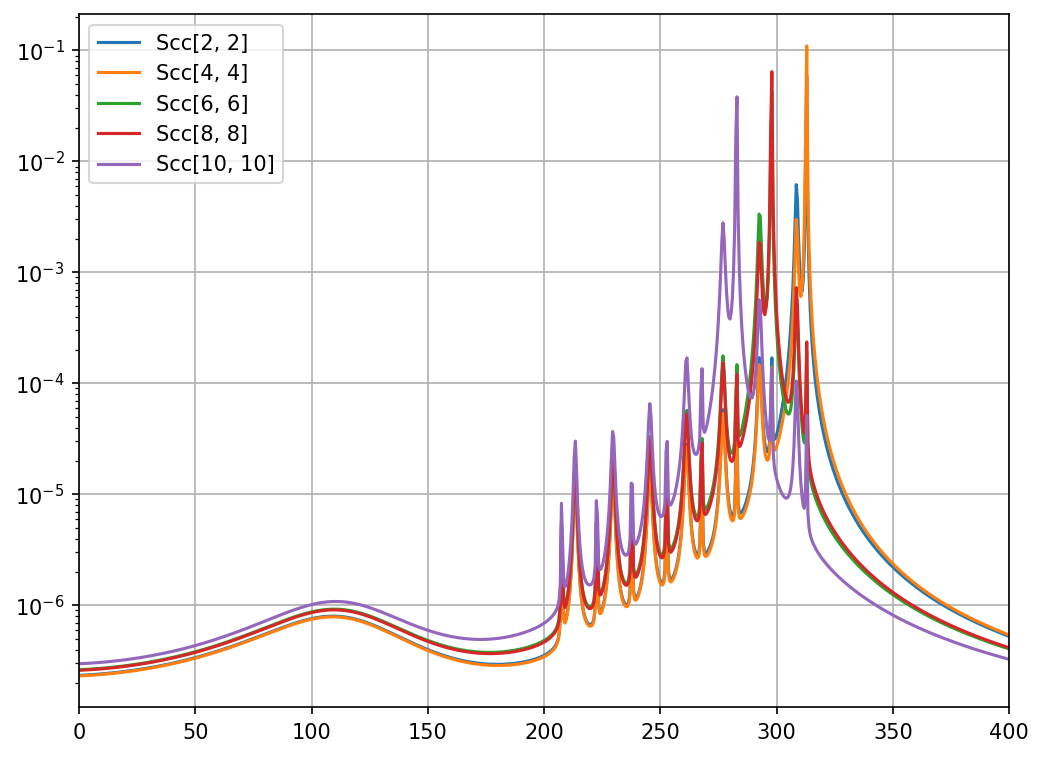

In [6]:
Scc = mph.quantum_operator_spectral_density_array
row, col = 2, 2
for row in np.arange(2, 12, 2):
    col = row
    # col = row + 1
    # row = col
    plt.plot(
        mph.ω_range / kHz,
        Scc[:, row, col] + Scc[:, row + 1, col + 1],
        label=f'Scc[{row}, {col}]',
    )
plt.yscale('log')
plt.legend()
plt.grid()
plt.xlim(ω_low, ω_high)
plt.show()


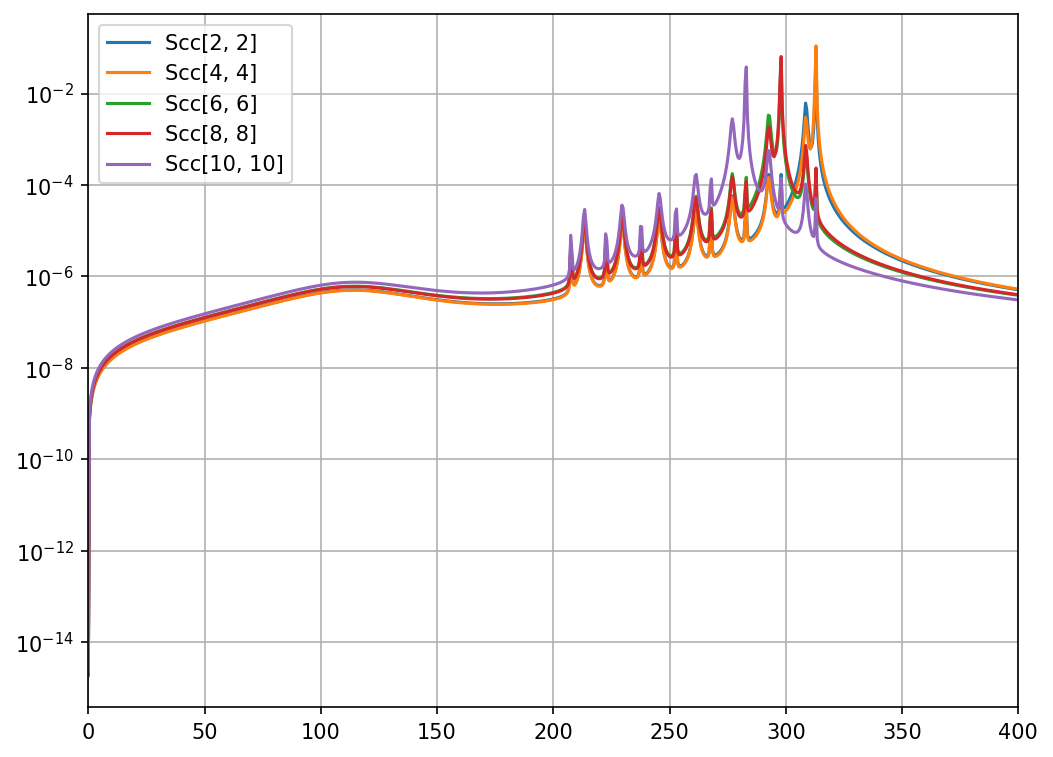

In [ ]:
# NOTE: momentum spectra???
Scc = mph.quantum_operator_spectral_density_array
row, col = 2, 2
for row in np.arange(2, 12, 2):
    col = row
    # col = row + 1
    # row = col
    plt.plot(
        mph.ω_range / kHz,
        # 1j * (Scc[:, row, col] - Scc[:, row + 1, col + 1]),
        np.abs(1j * (Scc[:, row + 1, col + 1] - Scc[:, row, col])),
        label=f'Scc[{row}, {col}]',
    )
plt.yscale('log')
plt.legend()
plt.grid()
plt.xlim(ω_low, ω_high)
plt.show()

/opt/homebrew/lib/python3.11/site-packages/matplotlib/cbook/__init__.py:1335: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


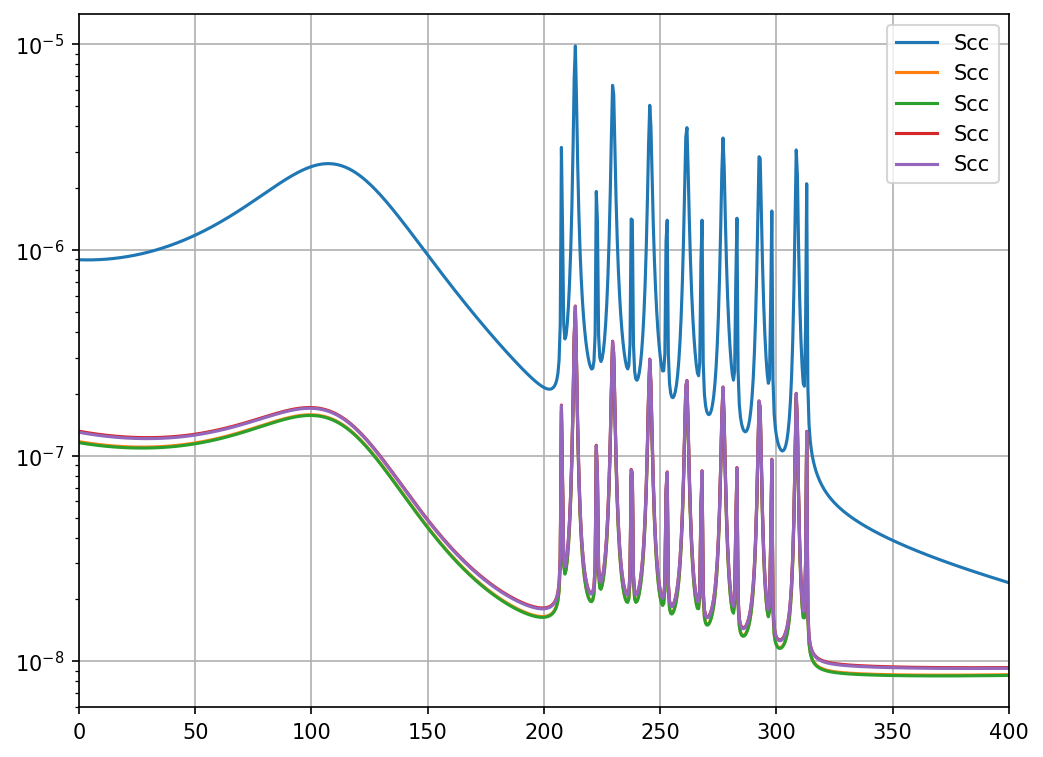

In [23]:
for ii in range(5):
    plt.plot(
        mph.ω_range / kHz,
        Scc[:, 2*ii + 1, 2*ii + 1],
        label='Scc',
    )
plt.yscale('log')
plt.legend()
plt.grid()
plt.xlim(ω_low, ω_high)
plt.show()

# Testing the generation of the "drift" matrix for Linear Amplifier Model (LAM)

## 1 × 3 system (1 bead $xyz$-motion)

In [16]:
def assert_equal_rows(rows, row_tests):
    row_ii = 0
    for row, row_test in zip(rows, row_tests):
        for _ in range(len(row_tests)):
            assert row[0, _] == row_test[_], f'Failed on row {row_ii}, index {_}'
        row_ii += 1

from multiphysics import *

mph1x3 = MultiPhysics(
    num_traps=1,
    Cartesian_axes_per_trap=3,
)
test_mph = mph1x3

iD = 1j * test_mph.cavity.Δ
K = test_mph.cavity.κ

cav = iD - K/2
cav_s = -iD - K/2

Ωx = test_mph.dimensions['x1'].Ω
Ωy = test_mph.dimensions['y1'].Ω
Ωz = test_mph.dimensions['z1'].Ω

Γx = test_mph.dimensions['x1'].Γ
Γy = test_mph.dimensions['y1'].Γ
Γz = test_mph.dimensions['z1'].Γ

m_x = -1j * Ωx - Γx/2
m_y = -1j * Ωy - Γy/2
m_z = -1j * Ωz - Γz/2

m_xs = 1j * Ωx - Γx/2
m_ys = 1j * Ωy - Γy/2
m_zs = 1j * Ωz - Γz/2

Gx = test_mph.dimensions['x1'].G
Gy = test_mph.dimensions['y1'].G
Gz = test_mph.dimensions['z1'].G

iGx = 1j * Gx
iGy = 1j * Gy
iGz = 1j * Gz

iGxs = 1j * np.conjugate(Gx)
iGys = 1j * np.conjugate(Gy)
iGzs = 1j * np.conjugate(Gz)

gxy = test_mph.dimensions['x1'].gxy
gyx = test_mph.dimensions['y1'].gxy
assert gxy == gyx, f'(gxy, gyx) = ({gxy / kHz}, {gyx / kHz}) kHz'

gyz = test_mph.dimensions['y1'].gyz
gzy = test_mph.dimensions['z1'].gyz
assert gyz == gzy, f'(gyz, gzy) = ({gyz / kHz}, {gzy / kHz}) kHz'

gxz = test_mph.dimensions['x1'].gxz
gzx = test_mph.dimensions['z1'].gxz
assert gxz == gzx, f'(gxz, gzx) = ({gxz / kHz}, {gzx / kHz}) kHz'

igxy = 1j * gxy
igxz = 1j * gxz
igyz = 1j * gyz

row_0 = test_mph.drift_matrix[0]
row_1 = test_mph.drift_matrix[1]
row_2 = test_mph.drift_matrix[2]
row_3 = test_mph.drift_matrix[3]
row_4 = test_mph.drift_matrix[4]
row_5 = test_mph.drift_matrix[5]
row_6 = test_mph.drift_matrix[6]
row_7 = test_mph.drift_matrix[7]

row_0_test = [
    cav, 0,
    iGx, iGx,
    iGy, iGy,
    iGz, iGz,
]
row_1_test = [
    0, cav_s,
    -iGxs, -iGxs,
    -iGys, -iGys,
    -iGzs, -iGzs,
]
row_2_test = [
    iGxs, iGx,
    m_x, 0,
    igxy, igxy,
    igxz, igxz,
]
row_3_test = [
    -iGxs, -iGx,
    0, m_xs,
    -igxy, -igxy,
    -igxz, -igxz,
]
row_4_test = [
    iGys, iGy,
    igxy, igxy,
    m_y, 0,
    igyz, igyz,
]
row_5_test = [
    -iGys, -iGy,
    -igxy, -igxy,
    0, m_ys,
    -igyz, -igyz,
]
row_6_test = [
    iGzs, iGz,
    igxz, igxz,
    igyz, igyz,
    m_z, 0,
]
row_7_test = [
    -iGzs, -iGz,
    -igxz, -igxz,
    -igyz, -igyz,
    0, m_zs,
]

rows = [
    row_0, row_1,
    row_2, row_3,
    row_4, row_5,
    row_6, row_7,
]
row_tests = [
    row_0_test, row_1_test,
    row_2_test, row_3_test,
    row_4_test, row_5_test,
    row_6_test, row_7_test,
]

assert_equal_rows(rows, row_tests)

## 2 × 2 system (2 beads $xy$-motion)

In [17]:
def assert_equal_rows(rows, row_tests):
    row_ii = 0
    for row, row_test in zip(rows, row_tests):
        for _ in range(len(row_tests)):
            assert row[0, _] == row_test[_], f'Failed on row {row_ii}, index {_}'
        row_ii += 1

from multiphysics import *

mph2x2 = MultiPhysics(
    num_traps=2,
    Cartesian_axes_per_trap=2,
)
test_mph = mph2x2

iD = 1j * test_mph.cavity.Δ
K = test_mph.cavity.κ

cav = iD - K/2
cav_s = -iD - K/2

Ωx1 = test_mph.dimensions['x1'].Ω
Ωy1 = test_mph.dimensions['y1'].Ω
Ωx2 = test_mph.dimensions['x2'].Ω
Ωy2 = test_mph.dimensions['y2'].Ω

Γx1 = test_mph.dimensions['x1'].Γ
Γy1 = test_mph.dimensions['y1'].Γ
Γx2 = test_mph.dimensions['x2'].Γ
Γy2 = test_mph.dimensions['y2'].Γ

m_x1 = -1j * Ωx1 - Γx1/2
m_y1 = -1j * Ωy1 - Γy1/2
m_x2 = -1j * Ωx2 - Γx2/2
m_y2 = -1j * Ωy2 - Γy2/2

m_x1s = 1j * Ωx1 - Γx1/2
m_y1s = 1j * Ωy1 - Γy1/2
m_x2s = 1j * Ωx2 - Γx2/2
m_y2s = 1j * Ωy2 - Γy2/2

Gx1 = test_mph.dimensions['x1'].G
Gy1 = test_mph.dimensions['y1'].G
Gx2 = test_mph.dimensions['x2'].G
Gy2 = test_mph.dimensions['y2'].G

iGx1 = 1j * Gx1
iGy1 = 1j * Gy1
iGx2 = 1j * Gx2
iGy2 = 1j * Gy2

iGx1s = 1j * np.conjugate(Gx1)
iGy1s = 1j * np.conjugate(Gy1)
iGx2s = 1j * np.conjugate(Gx2)
iGy2s = 1j * np.conjugate(Gy2)

gx1y1 = test_mph.dimensions['x1'].gxy
gy1x1 = test_mph.dimensions['y1'].gxy
assert gx1y1 == gy1x1, f'(gx1y1, gy1x1) = ({gx1y1 / kHz}, {gy1x1 / kHz}) kHz'

gx2y2 = test_mph.dimensions['x2'].gxy
gy2x2 = test_mph.dimensions['y2'].gxy
assert gx2y2 == gy2x2, f'(gx2y2, gy2x2) = ({gx2y2 / kHz}, {gy2x2 / kHz}) kHz'

igx1y1 = 1j * gx1y1
igx2y2 = 1j * gx2y2

igy2x2 = 1j * gy2x2

row_0 = test_mph.drift_matrix[0]
row_1 = test_mph.drift_matrix[1]
row_2 = test_mph.drift_matrix[2]
row_3 = test_mph.drift_matrix[3]
row_4 = test_mph.drift_matrix[4]
row_5 = test_mph.drift_matrix[5]
row_6 = test_mph.drift_matrix[6]
row_7 = test_mph.drift_matrix[7]
row_8 = test_mph.drift_matrix[8]
row_9 = test_mph.drift_matrix[9]

row_0_test = [
    cav, 0,
    iGx1, iGx1,
    iGy1, iGy1,
    iGx2, iGx2,
    iGy2, iGy2,
]
row_1_test = [
    0, cav_s,
    -iGx1s, -iGx1s,
    -iGy1s, -iGy1s,
    -iGx2s, -iGx2s,
    -iGy2s, -iGy2s,
]
row_2_test = [
    iGx1s, iGx1,
    m_x1, 0,
    igx1y1, igx1y1,
    0, 0,
    0, 0,
]
row_3_test = [
    -iGx1s, -iGx1,
    0, m_x1s,
    -igx1y1, -igx1y1,
    0, 0,
    0, 0,
]
row_4_test = [
    iGy1s, iGy1,
    igx1y1, igx1y1,
    m_y1, 0,
    0, 0,
    0, 0,
]
row_5_test = [
    -iGy1s, -iGy1,
    -igx1y1, -igx1y1,
    0, m_y1s,
    0, 0,
    0, 0,
]
row_6_test = [
    iGx2s, iGx2,
    0, 0,
    0, 0,
    m_x2, 0,
    igx2y2, igx2y2,
]
row_7_test = [
    -iGx2s, -iGx2,
    0, 0,
    0, 0,
    0, m_x2s,
    -igx2y2, -igx2y2,
]
row_8_test = [
    iGy2s, iGy2,
    0, 0,
    0, 0,
    igx2y2, igx2y2,
    m_y2, 0,
]
row_9_test = [
    -iGy2s, -iGy2,
    0, 0,
    0, 0,
    -igx2y2, -igx2y2,
    0, m_y2s,
]

rows = [
    row_0, row_1,
    row_2, row_3,
    row_4, row_5,
    row_6, row_7,
    row_8, row_9,
]
row_tests = [
    row_0_test, row_1_test,
    row_2_test, row_3_test,
    row_4_test, row_5_test,
    row_6_test, row_7_test,
    row_8_test, row_9_test,
]

assert_equal_rows(rows, row_tests)

## 2 × 3 system (2 beads $xyz$-motion)

In [18]:
def assert_equal_rows(rows, row_tests):
    row_ii = 0
    for row, row_test in zip(rows, row_tests):
        for _ in range(len(row_tests)):
            assert row[0, _] == row_test[_], f'Failed on row {row_ii}, index {_}'
        row_ii += 1

from multiphysics import *

mph2x3 = MultiPhysics(
    num_traps=2,
    Cartesian_axes_per_trap=3,
)
test_mph = mph2x3

iD = 1j * test_mph.cavity.Δ
K = test_mph.cavity.κ

cav = iD - K/2
cav_s = -iD - K/2

Ωx1 = test_mph.dimensions['x1'].Ω
Ωy1 = test_mph.dimensions['y1'].Ω
Ωz1 = test_mph.dimensions['z1'].Ω
Ωx2 = test_mph.dimensions['x2'].Ω
Ωy2 = test_mph.dimensions['y2'].Ω
Ωz2 = test_mph.dimensions['z2'].Ω

Γx1 = test_mph.dimensions['x1'].Γ
Γy1 = test_mph.dimensions['y1'].Γ
Γz1 = test_mph.dimensions['z1'].Γ
Γx2 = test_mph.dimensions['x2'].Γ
Γy2 = test_mph.dimensions['y2'].Γ
Γz2 = test_mph.dimensions['z2'].Γ

m_x1 = -1j * Ωx1 - Γx1/2
m_y1 = -1j * Ωy1 - Γy1/2
m_z1 = -1j * Ωz1 - Γz1/2
m_x2 = -1j * Ωx2 - Γx2/2
m_y2 = -1j * Ωy2 - Γy2/2
m_z2 = -1j * Ωz2 - Γz2/2

m_x1s = 1j * Ωx1 - Γx1/2
m_y1s = 1j * Ωy1 - Γy1/2
m_z1s = 1j * Ωz1 - Γz1/2
m_x2s = 1j * Ωx2 - Γx2/2
m_y2s = 1j * Ωy2 - Γy2/2
m_z2s = 1j * Ωz2 - Γz2/2

Gx1 = test_mph.dimensions['x1'].G
Gy1 = test_mph.dimensions['y1'].G
Gz1 = test_mph.dimensions['z1'].G
Gx2 = test_mph.dimensions['x2'].G
Gy2 = test_mph.dimensions['y2'].G
Gz2 = test_mph.dimensions['z2'].G

iGx1 = 1j * Gx1
iGy1 = 1j * Gy1
iGz1 = 1j * Gz1
iGx2 = 1j * Gx2
iGy2 = 1j * Gy2
iGz2 = 1j * Gz2

iGx1s = 1j * np.conjugate(Gx1)
iGy1s = 1j * np.conjugate(Gy1)
iGz1s = 1j * np.conjugate(Gz1)
iGx2s = 1j * np.conjugate(Gx2)
iGy2s = 1j * np.conjugate(Gy2)
iGz2s = 1j * np.conjugate(Gz2)

gx1y1 = test_mph.dimensions['x1'].gxy
gy1x1 = test_mph.dimensions['y1'].gxy
assert gx1y1 == gy1x1, f'(gx1y1, gy1x1) = ({gx1y1 / kHz}, {gy1x1 / kHz}) kHz'

gx1z1 = test_mph.dimensions['x1'].gxz
gz1x1 = test_mph.dimensions['z1'].gxz
assert gx1z1 == gz1x1, f'(gx1z1, gz1x1) = ({gx1z1 / kHz}, {gz1x1 / kHz}) kHz'

gy1z1 = test_mph.dimensions['y1'].gyz
gz1y1 = test_mph.dimensions['z1'].gyz
assert gy1z1 == gz1y1, f'(gy1z1, gz1y1) = ({gy1z1 / kHz}, {gz1y1 / kHz}) kHz'

gx2y2 = test_mph.dimensions['x2'].gxy
gy2x2 = test_mph.dimensions['y2'].gxy
assert gx2y2 == gy2x2, f'(gx2y2, gy2x2) = ({gx2y2 / kHz}, {gy2x2 / kHz}) kHz'

gx2z2 = test_mph.dimensions['x2'].gxz
gz2x2 = test_mph.dimensions['z2'].gxz
assert gx2z2 == gz2x2, f'(gx2z2, gz2x2) = ({gx2z2 / kHz}, {gz2x2 / kHz}) kHz'

gy2z2 = test_mph.dimensions['y2'].gyz
gz2y2 = test_mph.dimensions['z2'].gyz
assert gy2z2 == gz2y2, f'(gy2z2, gz2y2) = ({gy2z2 / kHz}, {gz2y2 / kHz}) kHz'


igx1y1 = 1j * gx1y1
igx1z1 = 1j * gx1z1
igy1z1 = 1j * gy1z1

igx2y2 = 1j * gx2y2
igx2z2 = 1j * gx2z2
igy2z2 = 1j * gy2z2

row_0 = test_mph.drift_matrix[0]
row_1 = test_mph.drift_matrix[1]
row_2 = test_mph.drift_matrix[2]
row_3 = test_mph.drift_matrix[3]
row_4 = test_mph.drift_matrix[4]
row_5 = test_mph.drift_matrix[5]
row_6 = test_mph.drift_matrix[6]
row_7 = test_mph.drift_matrix[7]
row_8 = test_mph.drift_matrix[8]
row_9 = test_mph.drift_matrix[9]
row_10 = test_mph.drift_matrix[10]
row_11 = test_mph.drift_matrix[11]
row_12 = test_mph.drift_matrix[12]
row_13 = test_mph.drift_matrix[13]

row_0_test = [
    cav, 0,
    iGx1, iGx1,
    iGy1, iGy1,
    iGz1, iGz1,
    iGx2, iGx2,
    iGy2, iGy2,
    iGz2, iGz2,
]
row_1_test = [
    0, cav_s,
    -iGx1s, -iGx1s,
    -iGy1s, -iGy1s,
    -iGz1s, -iGz1s,
    -iGx2s, -iGx2s,
    -iGy2s, -iGy2s,
    -iGz2s, -iGz2s,
]
row_2_test = [
    iGx1s, iGx1,
    m_x1, 0,
    igx1y1, igx1y1,
    igx1z1, igx1z1,
    0, 0,
    0, 0,
    0, 0,
]
row_3_test = [
    -iGx1s, -iGx1,
    0, m_x1s,
    -igx1y1, -igx1y1,
    -igx1z1, -igx1z1,
    0, 0,
    0, 0,
    0, 0,
]
row_4_test = [
    iGy1s, iGy1,
    igx1y1, igx1y1,
    m_y1, 0,
    igy1z1, igy1z1,
    0, 0,
    0, 0,
    0, 0,
]
row_5_test = [
    -iGy1s, -iGy1,
    -igx1y1, -igx1y1,
    0, m_y1s,
    -igy1z1, -igy1z1,
    0, 0,
    0, 0,
    0, 0,
]
row_6_test = [
    iGz1s, iGz1,
    igx1z1, igx1z1,
    igy1z1, igy1z1,
    m_z1, 0,
    0, 0,
    0, 0,
    0, 0,
]
row_7_test = [
    -iGz1s, -iGz1,
    -igx1z1, -igx1z1,
    -igy1z1, -igy1z1,
    0, m_z1s,
    0, 0,
    0, 0,
    0, 0,
]

row_8_test = [
    iGx2s, iGx2,
    0, 0,
    0, 0,
    0, 0,
    m_x2, 0,
    igx2y2, igx2y2,
    igx2z2, igx2z2,
]
row_9_test = [
    -iGx2s, -iGx2,
    0, 0,
    0, 0,
    0, 0,
    0, m_x2s,
    -igx2y2, -igx2y2,
    -igx2z2, -igx2z2,
]
row_10_test = [
    iGy2s, iGy2,
    0, 0,
    0, 0,
    0, 0,
    igx2y2, igx2y2,
    m_y2, 0,
    igy2z2, igy2z2,
]
row_11_test = [
    -iGy2s, -iGy2,
    0, 0,
    0, 0,
    0, 0,
    -igx2y2, -igx2y2,
    0, m_y2s,
    -igy2z2, -igy2z2,
]
row_12_test = [
    iGz2s, iGz2,
    0, 0,
    0, 0,
    0, 0,
    igx2z2, igx2z2,
    igy2z2, igy2z2,
    m_z2, 0,
]
row_13_test = [
    -iGz2s, -iGz2,
    0, 0,
    0, 0,
    0, 0,
    -igx2z2, -igx2z2,
    -igy2z2, -igy2z2,
    0, m_z2s,
]
rows = [
    row_0, row_1,
    row_2, row_3,
    row_4, row_5,
    row_6, row_7,
    row_8, row_9,
    row_10, row_11,
    row_12, row_13,
]
row_tests = [
    row_0_test, row_1_test,
    row_2_test, row_3_test,
    row_4_test, row_5_test,
    row_6_test, row_7_test,
    row_8_test, row_9_test,
    row_10_test, row_11_test,
    row_12_test, row_13_test,
]

assert_equal_rows(rows, row_tests)